In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r'C:\Users\HP\Downloads\meta_ads_campaign_performance_synthetic (1).csv')

In [3]:
df.head(2)

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
0,2025-04-13,CMP10001,Brand Awareness,Lookalike 1%,Facebook,Lead Generation,Feed,Healthcare,Telangana,188455,3538,31887.74,217.0,1259725.17,1.877,9.01,169.21,146.95,39.51
1,2025-06-29,CMP10002,Sales - Summer,Cart Abandoners,Facebook,App Promotion,Stories,FinTech,Uttar Pradesh,248383,1925,18504.90,70.0,53269.13,0.775,NaN,74.50,264.36,2.88


In [4]:
# basic information

In [5]:
df.shape

(2508, 19)

In [6]:
df.columns

Index(['date', 'campaign_id', 'campaign_name', 'ad_set', 'platform',
       'campaign_objective', 'placement', 'industry', 'region', 'impressions',
       'clicks', 'spend_inr', 'conversions', 'revenue_inr', 'ctr_pct',
       'cpc_inr', 'cpm_inr', 'cpa_inr', 'roas'],
      dtype='object')

In [7]:
# check random row

In [8]:
df.sample(5, random_state = 4)

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
2482,2025-06-16,CMP12483,Brand Awareness,Website Visitors,Instagram,Traffic,Reels,Real Estate,Uttar Pradesh,140786,2610,66513.03,144.0,298899.82,1.854,25.48,472.44,461.90,4.49
175,2025-06-01,CMP10176,Brand Awareness,Broad Audience,Facebook,Traffic,Right Column,Travel,Telangana,79797,1124,38575.78,79.0,163044.53,1.409,34.32,483.42,488.30,4.23
2095,2025-05-29,CMP12096,Sales - Summer,Lookalike 1%,Facebook,Traffic,Reels,Real Estate,Maharashtra,49273,829,19945.05,46.0,104801.51,1.682,24.06,404.79,433.59,5.25
1071,2025-01-05,CMP11072,Lead Gen - India,Interest - Tech,Facebook,App Promotion,Reels,Travel,NaN,79828,1675,37822.58,61.0,284976.61,2.098,22.58,473.80,620.04,7.53
1546,2025-04-09,CMP11547,Sales - Summer,Website Visitors,Facebook,Lead Generation,In-stream Video,Education,Maharashtra,232557,1346,17363.88,149.0,816010.80,0.579,12.90,74.67,116.54,46.99


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2508 entries, 0 to 2507
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                2508 non-null   object 
 1   campaign_id         2508 non-null   object 
 2   campaign_name       2508 non-null   object 
 3   ad_set              2508 non-null   object 
 4   platform            2508 non-null   object 
 5   campaign_objective  2508 non-null   object 
 6   placement           2508 non-null   object 
 7   industry            2508 non-null   object 
 8   region              2478 non-null   object 
 9   impressions         2508 non-null   int64  
 10  clicks              2508 non-null   int64  
 11  spend_inr           2508 non-null   float64
 12  conversions         2493 non-null   float64
 13  revenue_inr         2508 non-null   float64
 14  ctr_pct             2508 non-null   float64
 15  cpc_inr             2488 non-null   float64
 16  cpm_in

In [10]:
df.isna().sum().sort_values(ascending = False)

region                30
cpc_inr               20
conversions           15
cpa_inr                6
date                   0
clicks                 0
cpm_inr                0
ctr_pct                0
revenue_inr            0
spend_inr              0
impressions            0
campaign_id            0
industry               0
placement              0
campaign_objective     0
platform               0
ad_set                 0
campaign_name          0
roas                   0
dtype: int64

In [11]:
# missing Values

In [12]:
data = {"missing_counts" : df.isnull().sum(),
    "missing_percentage": (df.isnull().sum()/len(df)*100).round(2)}

In [13]:
data

{'missing_counts': date                   0
 campaign_id            0
 campaign_name          0
 ad_set                 0
 platform               0
 campaign_objective     0
 placement              0
 industry               0
 region                30
 impressions            0
 clicks                 0
 spend_inr              0
 conversions           15
 revenue_inr            0
 ctr_pct                0
 cpc_inr               20
 cpm_inr                0
 cpa_inr                6
 roas                   0
 dtype: int64,
 'missing_percentage': date                  0.00
 campaign_id           0.00
 campaign_name         0.00
 ad_set                0.00
 platform              0.00
 campaign_objective    0.00
 placement             0.00
 industry              0.00
 region                1.20
 impressions           0.00
 clicks                0.00
 spend_inr             0.00
 conversions           0.60
 revenue_inr           0.00
 ctr_pct               0.00
 cpc_inr               0.80
 cp

In [14]:
missing_summary = pd.DataFrame(data)

In [15]:
missing_summary

,missing_counts,missing_percentage
date,0,0.00
campaign_id,0,0.00
campaign_name,0,0.00
ad_set,0,0.00
platform,0,0.00
campaign_objective,0,0.00
placement,0,0.00
industry,0,0.00
region,30,1.20
impressions,0,0.00


In [16]:
# check duplicate row present or not


In [17]:
print("total duplicate rows: ",df.duplicated().sum())

total duplicate rows:  8


In [18]:
a = df.duplicated(keep = False)
df[a]

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
170,2025-05-17,CMP10171,Retargeting,Broad Audience,Facebook,App Promotion,Reels,Healthcare,Tamil Nadu,196750,4412,109708.52,246.0,1164298.10,2.242,24.87,557.60,445.97,10.61
240,2025-04-09,CMP10241,Sales - Summer,Lookalike 1%,Facebook,Conversions,Stories,E-commerce,Tamil Nadu,72008,1432,15484.11,120.0,63163.36,1.989,10.81,215.03,129.03,4.08
432,2025-05-17,CMP10433,Brand Awareness,Cart Abandoners,Facebook,Conversions,Feed,E-commerce,Telangana,151584,2998,103958.03,174.0,57630.61,1.978,34.68,685.81,597.46,0.55
474,2025-04-06,CMP10475,Lead Gen - India,Broad Audience,Facebook,App Promotion,In-stream Video,E-commerce,Uttar Pradesh,249790,2038,39349.66,121.0,155306.30,0.816,19.31,157.53,325.20,3.95
921,2025-04-04,CMP10922,Sales - Summer,Broad Audience,Instagram,Reach,In-stream Video,FinTech,Tamil Nadu,65399,808,25806.91,46.0,273138.49,1.235,31.94,394.61,561.02,10.58
997,2025-06-27,CMP10998,Sales - Summer,Cart Abandoners,Instagram,Traffic,In-stream Video,Real Estate,Uttar Pradesh,7853,87,1985.08,7.0,23273.25,1.108,22.82,252.78,283.58,11.72
2225,2025-03-10,CMP12226,Brand Awareness,Interest - Tech,Facebook,Lead Generation,In-stream Video,FinTech,Telangana,213830,2253,18966.57,104.0,156974.92,1.054,8.42,88.70,182.37,8.28
2450,2025-04-07,CMP12451,App Installs,Broad Audience,Facebook,App Promotion,Reels,Education,Tamil Nadu,17054,381,5254.16,5.0,14206.73,2.234,13.79,308.09,1050.83,2.70
2500,2025-05-17,CMP10171,Retargeting,Broad Audience,Facebook,App Promotion,Reels,Healthcare,Tamil Nadu,196750,4412,109708.52,246.0,1164298.10,2.242,24.87,557.60,445.97,10.61
2501,2025-03-10,CMP12226,Brand Awareness,Interest - Tech,Facebook,Lead Generation,In-stream Video,FinTech,Telangana,213830,2253,18966.57,104.0,156974.92,1.054,8.42,88.70,182.37,8.28


## Date Range


In [19]:
pd.to_datetime(df['date'])

0      2025-04-13
1      2025-06-29
2      2025-04-03
3      2025-01-15
4      2025-04-17
          ...    
2503   2025-06-27
2504   2025-04-09
2505   2025-05-17
2506   2025-04-06
2507   2025-04-04
Name: date, Length: 2508, dtype: datetime64[ns]

In [20]:
df['date'] = pd.to_datetime(df['date'])

In [21]:
print("start_date:", df['date'].min())
print("end_date:", df['date'].max())
print("unique date: ",df['date'].nunique())

start_date: 2025-01-01 00:00:00
end_date: 2025-06-30 00:00:00
unique date:  181


## Data cleaning

In [22]:
# base on inspection we do data cleaning part

In [23]:
#drop duplicate

In [24]:
clean_df = df.drop_duplicates().copy()

In [25]:
clean_df

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
0,2025-04-13,CMP10001,Brand Awareness,Lookalike 1%,Facebook,Lead Generation,Feed,Healthcare,Telangana,188455,3538,31887.74,217.0,1259725.17,1.877,9.01,169.21,146.95,39.51
1,2025-06-29,CMP10002,Sales - Summer,Cart Abandoners,Facebook,App Promotion,Stories,FinTech,Uttar Pradesh,248383,1925,18504.90,70.0,53269.13,0.775,NaN,74.50,264.36,2.88
2,2025-04-03,CMP10003,Retargeting,Broad Audience,Audience Network,Conversions,Right Column,E-commerce,Gujarat,44177,513,11144.05,45.0,167103.96,1.161,21.72,252.26,247.65,14.99
3,2025-01-15,CMP10004,App Installs,Interest - Tech,Instagram,Lead Generation,Feed,Healthcare,Telangana,121903,1233,18067.66,51.0,39332.59,1.011,14.65,148.21,354.27,2.18
4,2025-04-17,CMP10005,Retargeting,Website Visitors,Instagram,Traffic,In-stream Video,Education,Karnataka,44056,732,12493.34,83.0,95676.18,1.662,17.07,283.58,150.52,7.66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2025-01-26,CMP12496,Lead Gen - India,Lookalike 1%,Instagram,App Promotion,In-stream Video,Healthcare,Gujarat,82027,1092,29672.94,108.0,442821.70,1.331,27.17,361.75,274.75,14.92
2496,2025-02-03,CMP12497,App Installs,Broad Audience,Facebook,Conversions,Stories,Education,Karnataka,186880,2382,69190.70,164.0,280211.36,1.275,29.05,370.24,421.89,4.05
2497,2025-02-21,CMP12498,Sales - Summer,Broad Audience,Instagram,Lead Generation,Feed,Real Estate,Delhi NCR,44530,483,5718.96,41.0,202870.41,1.085,11.84,128.43,139.49,35.47
2498,2025-04-22,CMP12499,Retargeting,Broad Audience,Facebook,Traffic,In-stream Video,Education,Delhi NCR,144906,1450,30046.46,94.0,374988.61,1.001,20.72,207.35,319.64,12.48


## missing values

In [26]:
# cat missing value

In [27]:
clean_df['region'] = clean_df['region'].fillna("Unknown")

In [28]:
clean_df['region'].isna().sum()

np.int64(0)

In [29]:
# numerical data


In [30]:
clean_df['cpc_inr']

0        9.01
1         NaN
2       21.72
3       14.65
4       17.07
        ...  
2495    27.17
2496    29.05
2497    11.84
2498    20.72
2499    20.38
Name: cpc_inr, Length: 2500, dtype: float64

In [31]:
clean_df['spend_inr']

0       31887.74
1       18504.90
2       11144.05
3       18067.66
4       12493.34
          ...   
2495    29672.94
2496    69190.70
2497     5718.96
2498    30046.46
2499    69038.17
Name: spend_inr, Length: 2500, dtype: float64

In [32]:
clean_df['cpc_inr'] = (clean_df['spend_inr'] / clean_df['cpc_inr']).round(2)

In [33]:
clean_df['conversions'] = clean_df['conversions'].fillna(clean_df['conversions'].median())

In [34]:
clean_df['cpa_inr'] = clean_df['cpa_inr'].fillna(clean_df['cpa_inr'].median())

In [35]:
clean_df

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
0,2025-04-13,CMP10001,Brand Awareness,Lookalike 1%,Facebook,Lead Generation,Feed,Healthcare,Telangana,188455,3538,31887.74,217.0,1259725.17,1.877,3539.15,169.21,146.95,39.51
1,2025-06-29,CMP10002,Sales - Summer,Cart Abandoners,Facebook,App Promotion,Stories,FinTech,Uttar Pradesh,248383,1925,18504.90,70.0,53269.13,0.775,NaN,74.50,264.36,2.88
2,2025-04-03,CMP10003,Retargeting,Broad Audience,Audience Network,Conversions,Right Column,E-commerce,Gujarat,44177,513,11144.05,45.0,167103.96,1.161,513.08,252.26,247.65,14.99
3,2025-01-15,CMP10004,App Installs,Interest - Tech,Instagram,Lead Generation,Feed,Healthcare,Telangana,121903,1233,18067.66,51.0,39332.59,1.011,1233.29,148.21,354.27,2.18
4,2025-04-17,CMP10005,Retargeting,Website Visitors,Instagram,Traffic,In-stream Video,Education,Karnataka,44056,732,12493.34,83.0,95676.18,1.662,731.89,283.58,150.52,7.66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2025-01-26,CMP12496,Lead Gen - India,Lookalike 1%,Instagram,App Promotion,In-stream Video,Healthcare,Gujarat,82027,1092,29672.94,108.0,442821.70,1.331,1092.12,361.75,274.75,14.92
2496,2025-02-03,CMP12497,App Installs,Broad Audience,Facebook,Conversions,Stories,Education,Karnataka,186880,2382,69190.70,164.0,280211.36,1.275,2381.78,370.24,421.89,4.05
2497,2025-02-21,CMP12498,Sales - Summer,Broad Audience,Instagram,Lead Generation,Feed,Real Estate,Delhi NCR,44530,483,5718.96,41.0,202870.41,1.085,483.02,128.43,139.49,35.47
2498,2025-04-22,CMP12499,Retargeting,Broad Audience,Facebook,Traffic,In-stream Video,Education,Delhi NCR,144906,1450,30046.46,94.0,374988.61,1.001,1450.12,207.35,319.64,12.48


## feature engineering

In [ ]:
# ctr
df["ctr_pct"] = (clean_df["clicks"] / clean_df['impressions']*100).round(3)

#cpc
df["cpc_pct"] = (clean_df["spend_inr"] / clean_df['clicks'])

# cpm
df["cpm_pct"] = (clean_df["spend_inr"] / clean_df['impressions']*1000).round(3)

In [ ]:
df["ctr_pct"]

In [ ]:
df["cpc_pct"]

In [38]:
clean_df['platform'].value_counts()

platform
Instagram           1116
Facebook            1091
Audience Network     205
Messenger             88
Name: count, dtype: int64

<Axes: xlabel='platform', ylabel='count'>

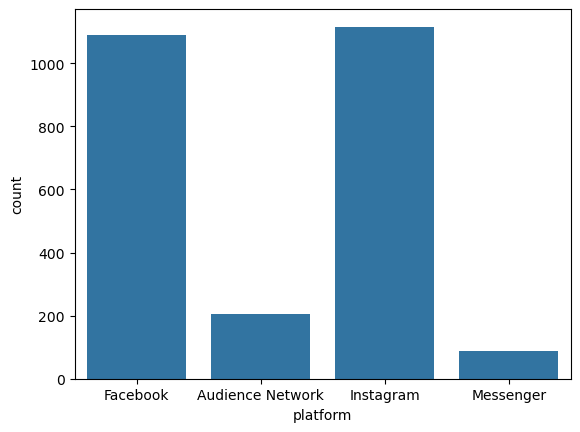

In [39]:
sns.countplot(data=clean_df,x = "platform")

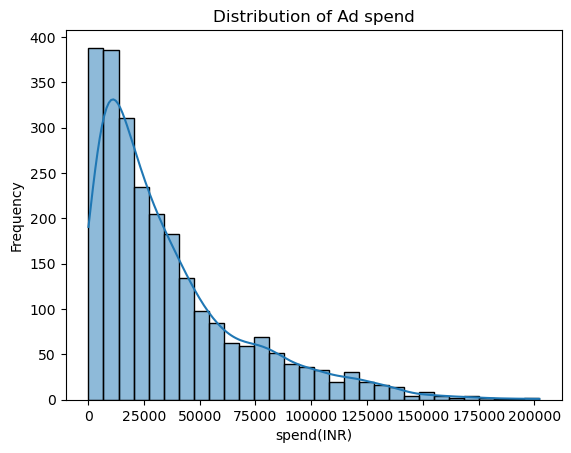

In [44]:
sns.histplot(data=clean_df,x = "spend_inr", bins = 30, kde = True)
plt.title("Distribution of Ad spend")
plt.xlabel("spend(INR)")
plt.ylabel("Frequency")
plt.show()

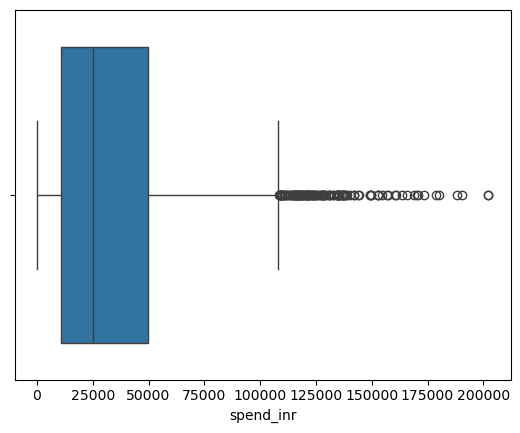

In [47]:
sns.boxplot(data = clean_df, x = "spend_inr")
plt.show()

In [48]:
Q1 = clean_df["spend_inr"].quantile(0.25)

In [50]:
Q3 = clean_df["spend_inr"].quantile(0.75)

In [52]:
iqr = Q3 - Q1

In [59]:
higher_boundary = Q3 + 1.5 * iqr

In [60]:
print(higher_boundary)

108060.34749999999


In [61]:
clean_df[clean_df["spend_inr"]>higher_boundary]

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
9,2025-03-16,CMP10010,Sales - Summer,Website Visitors,Instagram,Conversions,Reels,E-commerce,Tamil Nadu,213294,3914,134559.84,89.0,440472.69,1.835,3913.90,630.87,1511.91,3.27
24,2025-06-10,CMP10025,App Installs,Interest - Tech,Instagram,App Promotion,In-stream Video,Real Estate,Delhi NCR,216190,4645,138225.88,394.0,1848274.61,2.149,4644.69,639.37,350.83,13.37
30,2025-06-19,CMP10031,App Installs,Lookalike 1%,Messenger,Lead Generation,Stories,Education,Tamil Nadu,237153,5091,135397.16,243.0,699166.91,2.147,5090.12,570.93,557.19,5.16
50,2025-02-22,CMP10051,Brand Awareness,Broad Audience,Instagram,Conversions,Stories,FinTech,Telangana,210765,4821,120427.55,69.0,91494.40,2.287,4820.96,571.38,1745.33,0.76
51,2025-05-10,CMP10052,App Installs,Website Visitors,Audience Network,App Promotion,Stories,E-commerce,Maharashtra,236771,4793,128568.13,212.0,618228.69,2.024,4793.74,543.01,606.45,4.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2410,2025-06-22,CMP12411,Lead Gen - India,Interest - Tech,Instagram,App Promotion,Feed,E-commerce,Tamil Nadu,240253,4652,137391.47,193.0,792916.22,1.936,4652.61,571.86,711.87,5.77
2416,2025-05-21,CMP12417,App Installs,Cart Abandoners,Messenger,Reach,Feed,Travel,Gujarat,183473,4427,121347.39,425.0,630705.78,2.413,4427.12,661.39,285.52,5.20
2423,2025-06-09,CMP12424,Sales - Summer,Website Visitors,Instagram,App Promotion,Right Column,FinTech,Delhi NCR,240114,4865,149125.16,511.0,2585001.93,2.026,4865.42,621.06,291.83,17.33
2428,2025-05-31,CMP12429,App Installs,Interest - Tech,Facebook,Lead Generation,In-stream Video,Healthcare,Maharashtra,239741,4576,121130.39,386.0,189077.10,1.909,4576.14,505.26,313.81,1.56


In [62]:
clean_df[clean_df["spend_inr"]<higher_boundary]

,date,campaign_id,campaign_name,ad_set,platform,campaign_objective,placement,industry,region,impressions,clicks,spend_inr,conversions,revenue_inr,ctr_pct,cpc_inr,cpm_inr,cpa_inr,roas
0,2025-04-13,CMP10001,Brand Awareness,Lookalike 1%,Facebook,Lead Generation,Feed,Healthcare,Telangana,188455,3538,31887.74,217.0,1259725.17,1.877,3539.15,169.21,146.95,39.51
1,2025-06-29,CMP10002,Sales - Summer,Cart Abandoners,Facebook,App Promotion,Stories,FinTech,Uttar Pradesh,248383,1925,18504.90,70.0,53269.13,0.775,NaN,74.50,264.36,2.88
2,2025-04-03,CMP10003,Retargeting,Broad Audience,Audience Network,Conversions,Right Column,E-commerce,Gujarat,44177,513,11144.05,45.0,167103.96,1.161,513.08,252.26,247.65,14.99
3,2025-01-15,CMP10004,App Installs,Interest - Tech,Instagram,Lead Generation,Feed,Healthcare,Telangana,121903,1233,18067.66,51.0,39332.59,1.011,1233.29,148.21,354.27,2.18
4,2025-04-17,CMP10005,Retargeting,Website Visitors,Instagram,Traffic,In-stream Video,Education,Karnataka,44056,732,12493.34,83.0,95676.18,1.662,731.89,283.58,150.52,7.66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,2025-01-26,CMP12496,Lead Gen - India,Lookalike 1%,Instagram,App Promotion,In-stream Video,Healthcare,Gujarat,82027,1092,29672.94,108.0,442821.70,1.331,1092.12,361.75,274.75,14.92
2496,2025-02-03,CMP12497,App Installs,Broad Audience,Facebook,Conversions,Stories,Education,Karnataka,186880,2382,69190.70,164.0,280211.36,1.275,2381.78,370.24,421.89,4.05
2497,2025-02-21,CMP12498,Sales - Summer,Broad Audience,Instagram,Lead Generation,Feed,Real Estate,Delhi NCR,44530,483,5718.96,41.0,202870.41,1.085,483.02,128.43,139.49,35.47
2498,2025-04-22,CMP12499,Retargeting,Broad Audience,Facebook,Traffic,In-stream Video,Education,Delhi NCR,144906,1450,30046.46,94.0,374988.61,1.001,1450.12,207.35,319.64,12.48


## Bivariate

In [67]:
print(clean_df[clean_df["platform"] == "Facebook"]["spend_inr"].sum())

38481021.92


In [69]:
clean_df.groupby("platform")['spend_inr'].sum()

platform
Audience Network     8012896.08
Facebook            38481021.92
Instagram           40117819.53
Messenger            3424040.58
Name: spend_inr, dtype: float64

In [73]:
platform_spend = clean_df.groupby("platform")['spend_inr'].sum().sort_values(ascending = False)

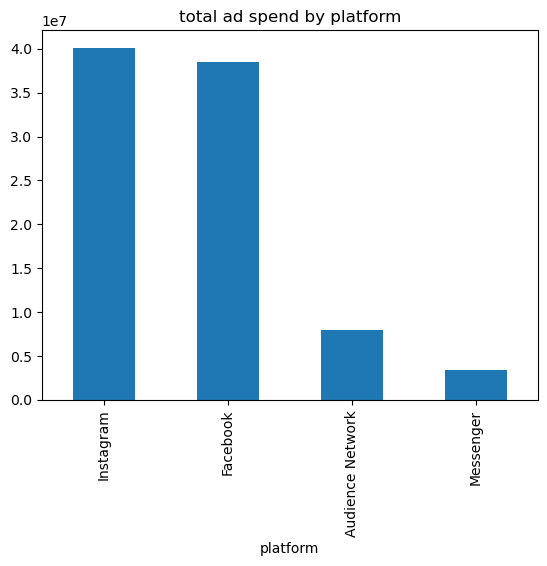

In [77]:
platform_spend.plot(kind="bar")
plt.title("total ad spend by platform")
plt.show()

## project summary

In [78]:
summary = """Meta Ads Campaign Performence-Managemt Summary
1. Business Object     ---> To evaluate advertising campign performance across platform, campaign objective placement and region.
2. Overall Performance ---> (a) Total advertising spend
                            (b) Overall ctr, cpa, roas
                            (c) Total Clicks"""

In [80]:
with open("Meta_ads_summary", "x") as file:
    file.write(summary)

FileExistsError: [Errno 17] File exists: 'Meta_ads_summary'